# Photo Retouch — Refinement Experiments

Advanced Mathematics for Deep Learning final project.

This notebook continues `photo_retouch_training.ipynb`. That notebook keeps
every earlier experiment with its outputs and is no longer extended. Its
reusable code now lives in the `photo_retouch` package (`src/photo_retouch/`),
so this notebook imports functions instead of redefining them.

Nothing here retrains earlier models. They are loaded from `models/`, and every
evaluation uses the frozen validation snapshot in `records/`. The first
sections restore that state and check it against the saved records.

## Setup

Install the package in the notebook's environment once (see ENVIRONMENT.md):

```bash
python -m pip install --no-build-isolation --no-deps -e .
```

The install is editable: after changing a file in `src/photo_retouch/`, restart
the kernel to use the new code. No reinstall is needed.

| Module | Contents |
| --- | --- |
| `data` | Image loading, the validation set, mixed masks, training batches |
| `models` | Coarse U-Net loading, gated-conv refiner, patch discriminator, refine functions |
| `features` | Frozen VGG16 and InceptionV3 extractors |
| `losses` | Masked L1, perceptual, style, and hinge losses |
| `training` | Loss-weight calibration, the adversarial refiner update, resumable training runs |
| `metrics` | Masked MAE, frequency errors, perceptual distance, KID, detail energy, grid test, paired comparisons |
| `plotting` | Side-by-side visual comparisons and enlarged crops |

In [1]:
import pandas as pd
import tensorflow as tf

from photo_retouch.data import load_validation_set
from photo_retouch.device import configure_device
from photo_retouch.metrics import Evaluator
from photo_retouch.models import (
    COARSE_MODEL_FILE,
    SAVED_REFINERS,
    load_saved_model,
    predict_coarse,
    refine_images,
)
from photo_retouch.plotting import show_comparison
from photo_retouch.training import saved_loss_weights

TRAINING_DEVICE = configure_device()
print(f"TensorFlow: {tf.__version__}")
print(f"Preferred device: {TRAINING_DEVICE}")

TensorFlow: 2.18.1
Preferred device: /GPU:0


## Load the Frozen Validation Setup

Read the 400 validation images and their fixed mixed masks from the experiment
snapshot. Preprocessing matches training: decode, scale to [0, 1], and resize
to 128 × 128. The fixed visual examples are the highest-coverage image of each
category.

In [2]:
validation = load_validation_set()
examples = validation.example_indices()

print(f"Snapshot: {validation.record_dir.name}")
print(f"Validation images: {len(validation)}")
print(f"Mean hole coverage: {validation.masks.mean():.1%}")

Snapshot: 20261117T213223_080287Z
Validation images: 400
Mean hole coverage: 13.7%


## Reconstruct the Validation Set with the Saved Models

The frozen coarse U-Net fills each hole, and each refiner refines that coarse
result. `SAVED_REFINERS` pairs every saved refiner with the function it was
trained with. The low-chroma refiners must be applied with
`refine_low_chroma`; with `refine`, their colours are wrong.

In [3]:
COARSE_NAME = "Deep U-Net (MAE reference)"

coarse_model = load_saved_model(COARSE_MODEL_FILE)
reconstructions = {COARSE_NAME: predict_coarse(coarse_model, validation)}

for name, (filename, refine_fn) in SAVED_REFINERS.items():
    refiner = load_saved_model(filename)
    reconstructions[name] = refine_images(
        refiner, reconstructions[COARSE_NAME], validation.masks, refine_fn
    )
    print(f"{name:<22} {filename:<28} {refine_fn.__name__}")

L1 refiner             refiner_l1_control.keras     refine


Texture refiner        refiner_texture.keras        refine


Low-chroma refiner     refiner_low_chroma.keras     refine_low_chroma


Low-chroma, no style   refiner_no_style.keras       refine_low_chroma


## Check the Restored State Against the Saved Records

Recompute every metric with the package and compare it with the tables saved
by the earlier notebook:

- the metric summaries of the refinement experiment and its follow-up;
- the paired comparisons of the follow-up variants;
- the colour-fringing (detail energy) ratios;
- the grid-periodicity test.

If the values match, the data, models, and metric code were carried over
unchanged. Any difference stops the notebook here.

In [4]:
evaluator = Evaluator(validation)
evaluations = {
    name: evaluator.evaluate(results) for name, results in reconstructions.items()
}

PAIRS = [
    ("Low-chroma refiner", COARSE_NAME),
    ("Low-chroma refiner", "Texture refiner"),
    ("Low-chroma, no style", COARSE_NAME),
    ("Low-chroma, no style", "Texture refiner"),
    ("Low-chroma, no style", "Low-chroma refiner"),
]

recomputed = {
    "metric_summary": pd.DataFrame({
        name: evaluation.summary() for name, evaluation in evaluations.items()
    }).T,
    "paired_comparisons": pd.DataFrame([
        {"method": method, "baseline": baseline,
         **evaluator.paired(evaluations[method], evaluations[baseline])}
        for method, baseline in PAIRS
    ]).set_index(["method", "baseline"]),
    "detail_energy": pd.DataFrame({
        name: evaluator.detail_summary(results)
        for name, results in reconstructions.items()
    }).T,
    "grid_periodicity": pd.DataFrame([
        {"method": name, **row}
        for name, images in {
            "True image": validation.originals, **reconstructions
        }.items()
        for row in evaluator.grid_periodicity(images)
    ]).set_index(["method", "direction"]),
}

In [5]:
REFINE_DIR = validation.record_dir / "refinement"
FOLLOWUP_DIR = validation.record_dir / "refinement_followup"
TOLERANCE = 1e-6

saved = {
    "metric_summary": pd.concat([
        pd.read_csv(REFINE_DIR / "metric_summary.csv", index_col="method"),
        pd.read_csv(FOLLOWUP_DIR / "metric_summary.csv", index_col="method"),
    ]),
    "paired_comparisons": pd.read_csv(
        FOLLOWUP_DIR / "paired_comparisons.csv", index_col=["method", "baseline"]
    ),
    "detail_energy": pd.read_csv(
        FOLLOWUP_DIR / "detail_energy.csv", index_col="method"
    ),
    "grid_periodicity": pd.read_csv(
        FOLLOWUP_DIR / "grid_periodicity_variants.csv",
        index_col=["method", "direction"],
    ),
}


def compare_with_record(new_table, saved_table):
    # Methods saved in both experiments appear twice; keep the latest row.
    saved_table = saved_table[~saved_table.index.duplicated(keep="last")]
    shared = new_table.index.intersection(saved_table.index)
    new = new_table.loc[shared, saved_table.columns]
    old = saved_table.loc[shared]
    numeric = old.select_dtypes("number").columns
    text = old.columns.difference(numeric)
    return {
        "rows compared": len(shared),
        "max numeric difference": (
            new[numeric].astype(float) - old[numeric]
        ).abs().max().max(),
        "text cells differing": int((new[text].astype(str) != old[text]).sum().sum()),
    }


state_check = pd.DataFrame({
    table: compare_with_record(recomputed[table], saved[table])
    for table in saved
}).T.astype({"rows compared": int, "text cells differing": int})
display(state_check)

assert (state_check["max numeric difference"] < TOLERANCE).all()
assert (state_check["text cells differing"] == 0).all()
print("The restored state reproduces the saved records.")

,rows compared,max numeric difference,text cells differing
metric_summary,5,2.761307e-08,0
paired_comparisons,5,4.880524e-09,0
detail_energy,4,4.330139e-08,0
grid_periodicity,8,0.000000e+00,0


The restored state reproduces the saved records.


## Results So Far

Pixel error, perceptual distance, and KID (lower is better for all three),
with the fine-detail energy in luminance and chroma relative to the true
images (1 matches the truth). The paired comparisons give image-by-image
differences with 95% bootstrap intervals; negative values favour the method.

In [6]:
overview = recomputed["metric_summary"][
    ["masked_mae", "feature_distance", "kid_x1000"]
].join(recomputed["detail_energy"][["luma_detail_ratio", "chroma_detail_ratio"]])

with pd.option_context("display.width", 200, "display.max_columns", 20):
    display(overview.round(4))
    display(recomputed["paired_comparisons"].round(4))

,masked_mae,feature_distance,kid_x1000,luma_detail_ratio,chroma_detail_ratio
Deep U-Net (MAE reference),0.0932,0.8803,4.7893,0.0292,0.2835
L1 refiner,0.0930,0.8758,4.6346,0.0279,0.2820
Texture refiner,0.1044,0.7057,-0.1895,0.6803,3.8364
Low-chroma refiner,0.1059,0.7083,0.0677,0.8070,1.0888
"Low-chroma, no style",0.0992,0.7229,0.4159,0.4707,0.7489


masked_mae Δ   masked_mae 95% CI masked_mae images better  feature_distance Δ feature_distance 95% CI feature_distance images better  KID×1000 Δ  \
method               baseline                                                                                                                                                                       
Low-chroma refiner   Deep U-Net (MAE reference)        0.0127  [+0.0117, +0.0136]                       6%             -0.1720      [-0.1875, -0.1572]                            93%     -4.7216   
                     Texture refiner                   0.0016  [+0.0012, +0.0020]                      36%              0.0027      [-0.0025, +0.0081]                            49%      0.2571   
Low-chroma, no style Deep U-Net (MAE reference)        0.0059  [+0.0053, +0.0065]                      11%             -0.1574      [-0.1704, -0.1450]                            96%     -4.3734   
                     Texture refiner                  -0.0052  [-0.0057, -0.0048]                      91%              0.0173      [+0.0101, +0.0243]                            42%      0.6053   
                     Low-chroma refiner               -0.0068  [-0.0073, -0.0063]                      95%              0.0146      [+0.0073, +0.0215]                            47%      0.3482   

                                                KID subsets lower  
method               baseline                                      
Low-chroma refiner   Deep U-Net (MAE reference)              100%  
                     Texture refiner                          16%  
Low-chroma, no style Deep U-Net (MAE reference)              100%  
                     Texture refiner                           9%  
                     Low-chroma refiner                       20%

## Visual Check

The coarse fill, the texture refiner, and both follow-up variants on the
fixed examples.

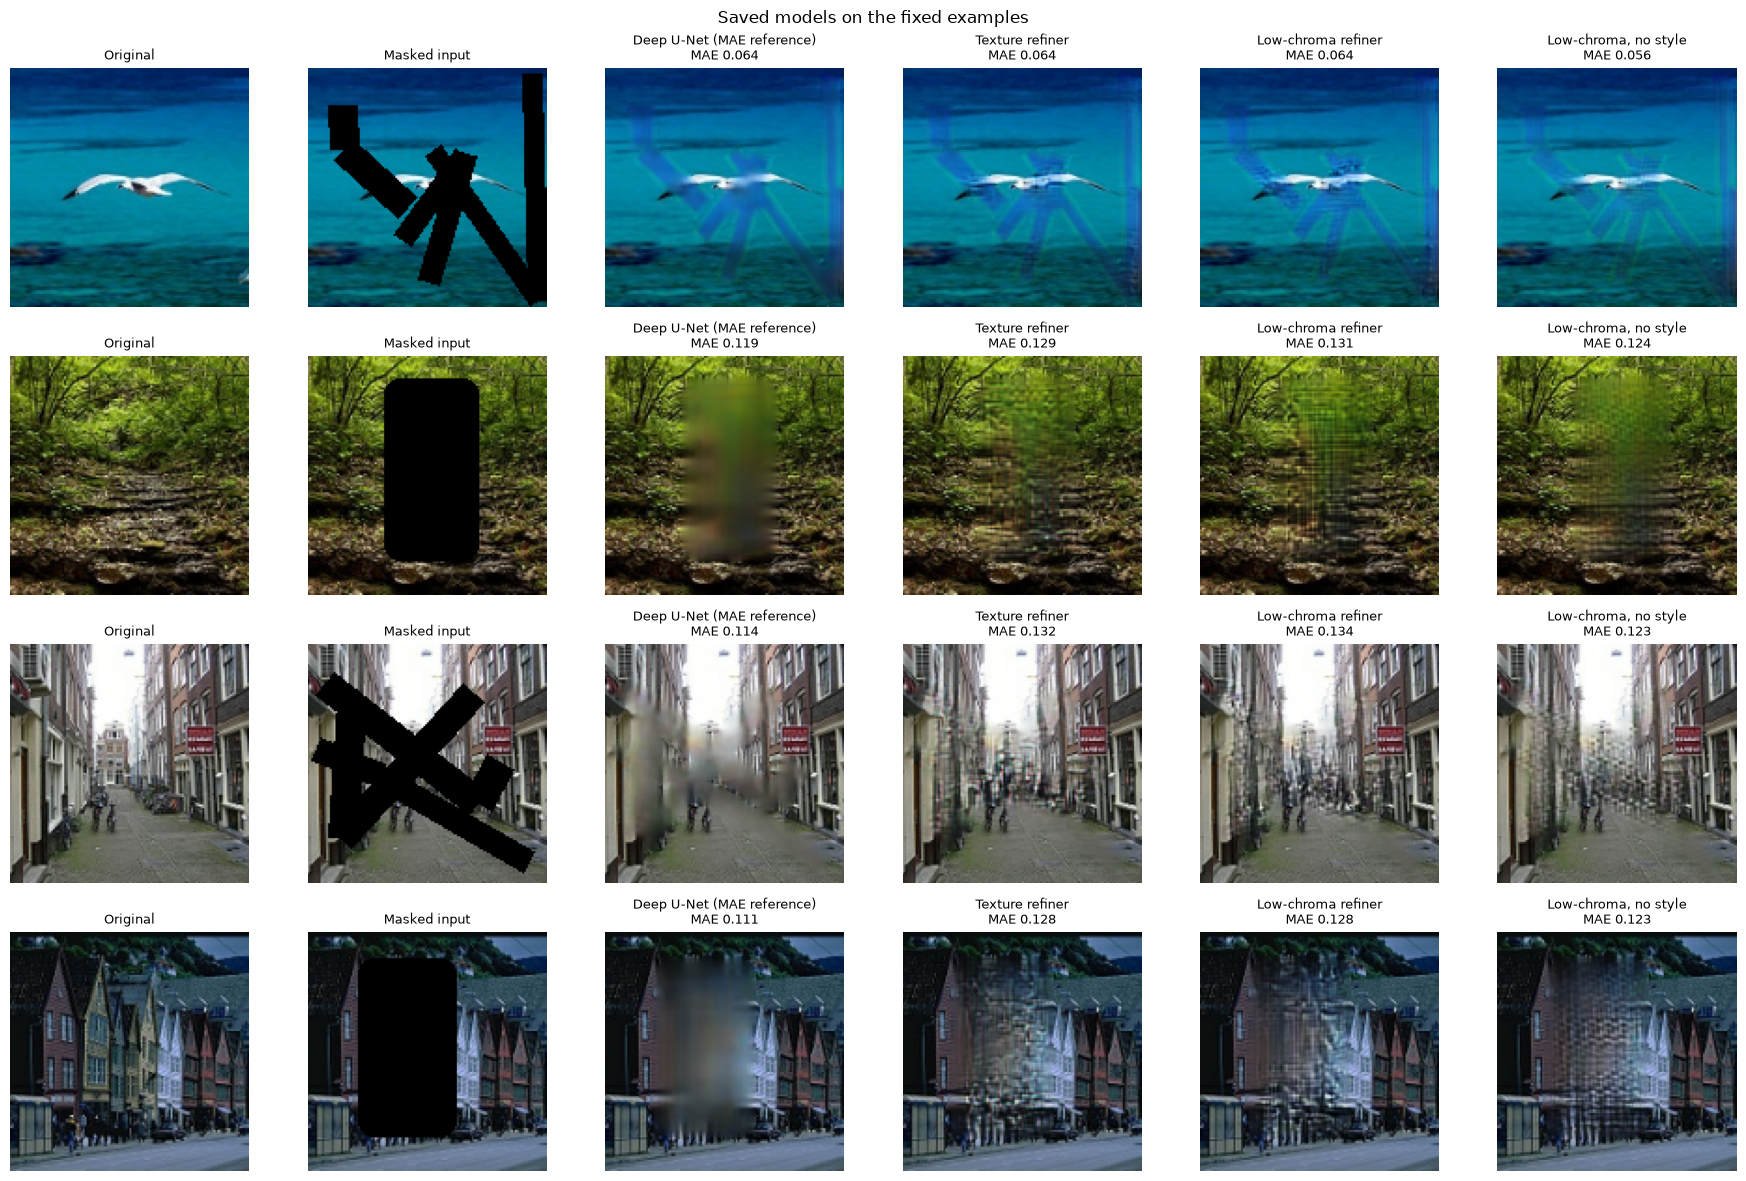

In [7]:
show_comparison(
    validation,
    {
        name: reconstructions[name]
        for name in [
            COARSE_NAME, "Texture refiner",
            "Low-chroma refiner", "Low-chroma, no style",
        ]
    },
    examples,
    "Saved models on the fixed examples",
)

## Training Settings Carried Over

The refiners were trained with loss weights calibrated so that the perceptual
and style gradients initially match the masked-L1 gradient, and with an
adaptive adversarial weight at half the reconstruction gradient. The values
are stored in the refinement checkpoint. `photo_retouch.training` also
provides the same training batches (`TrainingBatches`), the calibration
(`calibrate_loss_weights`), the adversarial update (`new_arm`,
`make_train_step`), and a checkpointed, resumable training loop
(`CheckpointedRun`) for new variants.

In [8]:
PERCEPTUAL_WEIGHT, STYLE_WEIGHT, ADV_RATIO = saved_loss_weights()

print(f"Perceptual weight: {PERCEPTUAL_WEIGHT:.4g}")
print(f"Style weight: {STYLE_WEIGHT:.4g}")
print(f"Adversarial ratio: {ADV_RATIO:g}")

Perceptual weight: 0.0002139
Style weight: 8.88e-05
Adversarial ratio: 0.5


## Starting Point

**Best candidate: the low-chroma refiner.** Compared with the coarse U-Net, it
lowers perceptual distance from 0.880 to 0.708 and KID × 1000 from 4.79 to
0.07, at a cost of 0.013 in masked MAE. It removes the texture refiner's
colour fringing (chroma detail 1.09 times the truth instead of 3.84) with no
measurable loss in perceptual distance.

**Open problem: a blocky luminance mosaic on facades.** Removing the style
loss made it worse, as Liu et al. (2018) report for perceptual losses without
a style term. Two causes remain untested:

1. **Style weight too small.** Liu et al. observe "fish scale" artifacts when
   the style weight is small. Ours was set by a gradient-norm heuristic, and
   its relative weight is much lower than theirs.
2. **Nearest-neighbour upsampling.** The low-chroma refiner has a 4-px grid
   component about twice that of the true images. That period matches the
   decoder's two ×2 nearest-neighbour upsampling layers.

**Human judgement is still missing.** The blind-review pages in `records/`
were generated before the refiners existed. A new panel that includes the
low-chroma refiner is needed to check whether the measured gain outweighs
the visible artifacts.

Each refiner variant is a single training run, so small differences may
reflect initialization rather than the change being tested.

## Experiment: Style Weight

**Question.** Is the blocky luminance mosaic of the low-chroma refiner caused
by a style weight that is too small?

Liu et al. (2018) report "fish scale" artifacts when the style weight is
small. Ours was set by equalizing gradient norms at initialization, not
tuned. Their weights (hole L1 6, perceptual 0.05, style 120) do not transfer
directly: the style term grows with the square of the feature scale and the
perceptual term only linearly, and our VGG16 receives 0–255 inputs. The
experiment therefore sweeps the weight over two orders of magnitude instead
of copying one value.

**Design.** Two new low-chroma refiners, with the calibrated style weight
multiplied by 10 and by 100. Everything else matches the earlier follow-up:
initialization (seed 2042), training images and masks, 3,000 updates,
perceptual weight, and adversarial ratio. With the existing variants (no
style, ×0; low-chroma refiner, ×1), this gives four points along one axis.
The adversarial weight is set relative to the reconstruction gradient, so it
rises in proportion; what changes is the balance between the style term and
L1 plus perceptual.

**Predictions.** If the weight is the cause, the grid-aligned components at
2 and 4 px should keep falling from ×0 to ×100 toward the level of the true
images, and facades should look less blocky. If they do not fall, the weight
is ruled out and the nearest-neighbour upsampling becomes the next test.

**Criterion for a new best candidate** (fixed before training). Compared with
the low-chroma refiner, a variant must:

1. lower the 2- and 4-px grid components in both directions, and
2. not worsen perceptual distance: the paired 95% interval must not lie
   entirely above zero.

KID differences smaller than one subset standard deviation (about 2 on the
×1000 scale) count as ties. Masked MAE is expected to rise as the style term
outweighs L1; it is reported as the cost, not used as a criterion.

In [9]:
from tensorflow import keras

from photo_retouch.data import TrainingBatches
from photo_retouch.features import LOSS_LAYERS, vgg16_features
from photo_retouch.models import (
    CHROMA_SIGMA,
    build_patch_discriminator,
    build_refiner,
    make_coarse_composite,
    refine_low_chroma,
)
from photo_retouch.paths import MODEL_DIR
from photo_retouch.training import CheckpointedRun, make_train_step, new_arm

INIT_SEED = 2042
STYLE_STEPS = 3000
STYLE_ARMS = {
    # name: (log key, multiple of the calibrated style weight)
    "Low-chroma, style ×10": ("style_x10", 10),
    "Low-chroma, style ×100": ("style_x100", 100),
}
STYLE_RECORD_DIR = validation.record_dir / "refinement_style_weight"
STYLE_CHECKPOINT_DIR = MODEL_DIR / "refinement_style_weight"
STYLE_MODEL_DIR = MODEL_DIR

batches = TrainingBatches()
coarse_composite = make_coarse_composite(coarse_model)
loss_features = vgg16_features(LOSS_LAYERS)

# The shared initialization of the earlier follow-up variants.
keras.utils.set_random_seed(INIT_SEED)
initial_refiner = build_refiner("followup_initial_refiner")
initial_discriminator = build_patch_discriminator()

style_arms = {
    name: new_arm(
        key, refine_low_chroma, multiple * STYLE_WEIGHT,
        initial_refiner, initial_discriminator,
    )
    for name, (key, multiple) in STYLE_ARMS.items()
}
for name, arm in style_arms.items():
    print(f"{name:<24} style weight {arm.style_weight:.3g}")

Low-chroma, style ×10    style weight 0.000888
Low-chroma, style ×100   style weight 0.00888


### Check the Shared Starting Point

The comparison with the ×0 and ×1 variants is controlled only if the new
arms start from the same weights and see the same batches. A ×1 arm built
from this initialization must reproduce the first two logged updates of the
saved low-chroma run.

In [10]:
followup_log = pd.read_csv(FOLLOWUP_DIR / "training_log.csv", index_col="step")

check_arm = new_arm(
    "low_chroma", refine_low_chroma, STYLE_WEIGHT,
    initial_refiner, initial_discriminator,
)
check_step = make_train_step(
    [check_arm], coarse_composite, loss_features, PERCEPTUAL_WEIGHT, ADV_RATIO
)
start_check = pd.DataFrame([
    {"step": step + 1, "value": name,
     "relative difference": abs(float(value) - followup_log.loc[step + 1, name])
     / abs(followup_log.loc[step + 1, name])}
    for step in range(2)
    for name, value in check_step(*batches(step)).items()
])
largest = start_check["relative difference"].max()
print(f"Largest relative difference over {len(start_check)} logged values: {largest:.1e}")
assert largest < 1e-5
del check_arm, check_step

Largest relative difference over 10 logged values: 0.0e+00


### Train

Both arms are updated on the same batch at every step. The run is
checkpointed every 250 updates; re-running this cell resumes from the last
checkpoint, or does nothing if all 3,000 updates are done. Logged values:
masked L1, perceptual and style (Gram) distances before weighting, the
discriminator's hinge loss, and the adaptive adversarial weight.

In [11]:
arms = list(style_arms.values())
style_run = CheckpointedRun(
    arms,
    make_train_step(arms, coarse_composite, loss_features, PERCEPTUAL_WEIGHT, ADV_RATIO),
    batches,
    STYLE_CHECKPOINT_DIR,
    STYLE_RECORD_DIR / "training_log.csv",
    settings={
        "perceptual_weight": PERCEPTUAL_WEIGHT,
        "adv_ratio": ADV_RATIO,
        "chroma_sigma": CHROMA_SIGMA,
        "init_seed": INIT_SEED,
        **{f"{arm.key}_style_weight": arm.style_weight for arm in arms},
    },
)
style_run.run(STYLE_STEPS)

for arm in arms:
    arm.refiner.save(STYLE_MODEL_DIR / f"refiner_{arm.key}.keras")
print(f"Completed updates per variant: {style_run.completed}")

Steps 1–250 (1.88 s/step)
  style_x10    L1: 0.1043 | Perc: 287.2 | Style: 689.6 | D: 1.917 | Adv weight: 1.19
  style_x100   L1: 0.1158 | Perc: 295.8 | Style: 704.4 | D: 1.911 | Adv weight: 12.2


Steps 251–500 (1.87 s/step)
  style_x10    L1: 0.1107 | Perc: 291.5 | Style: 548.8 | D: 1.881 | Adv weight: 0.305
  style_x100   L1: 0.1204 | Perc: 304.8 | Style: 577.9 | D: 1.849 | Adv weight: 2.98


Steps 501–750 (1.85 s/step)
  style_x10    L1: 0.1103 | Perc: 291.6 | Style: 502.3 | D: 1.798 | Adv weight: 0.279
  style_x100   L1: 0.1165 | Perc: 301.8 | Style: 520.3 | D: 1.802 | Adv weight: 2.11


Steps 751–1000 (1.88 s/step)
  style_x10    L1: 0.1123 | Perc: 292.2 | Style: 472.5 | D: 1.778 | Adv weight: 0.217
  style_x100   L1: 0.1186 | Perc: 300.9 | Style: 487.3 | D: 1.866 | Adv weight: 2.31


Steps 1001–1250 (1.86 s/step)
  style_x10    L1: 0.1169 | Perc: 294.5 | Style: 446.3 | D: 1.937 | Adv weight: 0.343
  style_x100   L1: 0.1196 | Perc: 301.5 | Style: 471.5 | D: 1.912 | Adv weight: 2.75


Steps 1251–1500 (1.86 s/step)
  style_x10    L1: 0.1141 | Perc: 287.3 | Style: 421.5 | D: 1.924 | Adv weight: 0.286
  style_x100   L1: 0.1192 | Perc: 298.7 | Style: 452.1 | D: 1.929 | Adv weight: 2.79


... (3 outputs left out)

Steps 2251–2500 (1.86 s/step)
  style_x10    L1: 0.1127 | Perc: 282.7 | Style: 396.4 | D: 1.945 | Adv weight: 0.297
  style_x100   L1: 0.1158 | Perc: 290.8 | Style: 412.7 | D: 1.941 | Adv weight: 2.6


Steps 2501–2750 (1.85 s/step)
  style_x10    L1: 0.1138 | Perc: 283.8 | Style: 392.5 | D: 1.945 | Adv weight: 0.299
  style_x100   L1: 0.1170 | Perc: 292.2 | Style: 406.4 | D: 1.945 | Adv weight: 2.56


Steps 2751–3000 (1.87 s/step)
  style_x10    L1: 0.1136 | Perc: 282.5 | Style: 391.3 | D: 1.946 | Adv weight: 0.293
  style_x100   L1: 0.1165 | Perc: 290.5 | Style: 405.6 | D: 1.946 | Adv weight: 2.79


Completed updates per variant: 3000


### Evaluate

The four low-chroma variants ordered by style weight. Grid components are
the strength of luminance jumps that repeat every 2 or 4 px, aligned with
the image grid (the true images' level is the reference). Detail ratios are
fine-detail energy relative to the truth (1 matches it). The Gram distance
is the training style loss, averaged over the last 250 updates.

In [12]:
STYLE_RECORD_DIR.mkdir(parents=True, exist_ok=True)

for name, arm in style_arms.items():
    reconstructions[name] = refine_images(
        arm.refiner, reconstructions[COARSE_NAME], validation.masks, refine_low_chroma
    )
    evaluations[name] = evaluator.evaluate(reconstructions[name])

STYLE_SERIES = {
    # multiple of the style weight: (method, log key)
    0: ("Low-chroma, no style", "no_style"),
    1: ("Low-chroma refiner", "low_chroma"),
    10: ("Low-chroma, style ×10", "style_x10"),
    100: ("Low-chroma, style ×100", "style_x100"),
}
style_logs = followup_log.join(style_run.log_frame().set_index("step"))
last_window = style_logs[style_logs.index > STYLE_STEPS - 250]


def grid_by_period(images):
    table = pd.DataFrame(evaluator.grid_periodicity(images)).set_index("direction")
    return {
        f"grid {period} px ({direction[0]})": table.loc[direction, f"period {period} px"]
        for period in [2, 4] for direction in ["horizontal", "vertical"]
    }


style_rows = []
for multiple, (name, key) in STYLE_SERIES.items():
    summary = evaluations[name].summary()
    detail = evaluator.detail_summary(reconstructions[name])
    style_rows.append({
        "style multiple": multiple,
        "method": name,
        "masked_mae": summary["masked_mae"],
        "feature_distance": summary["feature_distance"],
        "kid_x1000": summary["kid_x1000"],
        "luma_detail_ratio": detail["luma_detail_ratio"],
        "chroma_detail_ratio": detail["chroma_detail_ratio"],
        **grid_by_period(reconstructions[name]),
        "train_gram_distance": last_window[f"{key}_style"].mean(),
        "train_l1": last_window[f"{key}_l1"].mean(),
    })
style_table = pd.DataFrame(style_rows).set_index("style multiple")
true_grid = pd.Series(grid_by_period(validation.originals), name="True image")

STYLE_PAIRS = [
    (name, baseline)
    for name in STYLE_ARMS
    for baseline in [COARSE_NAME, "Low-chroma refiner"]
] + [("Low-chroma, style ×100", "Low-chroma, style ×10")]
style_paired = pd.DataFrame([
    {"method": method, "baseline": baseline,
     **evaluator.paired(evaluations[method], evaluations[baseline])}
    for method, baseline in STYLE_PAIRS
]).set_index(["method", "baseline"])

style_table.to_csv(STYLE_RECORD_DIR / "style_weight_summary.csv")
style_paired.to_csv(STYLE_RECORD_DIR / "paired_comparisons.csv")
pd.DataFrame({
    name: evaluations[name].summary() for name in STYLE_ARMS
}).T.rename_axis("method").to_csv(STYLE_RECORD_DIR / "metric_summary.csv")
pd.DataFrame([
    {"method": name, **row}
    for name, images in {
        "True image": validation.originals,
        **{name: reconstructions[name] for name in STYLE_ARMS},
    }.items()
    for row in evaluator.grid_periodicity(images)
]).set_index(["method", "direction"]).to_csv(STYLE_RECORD_DIR / "grid_periodicity.csv")

with pd.option_context("display.width", 250, "display.max_columns", 20):
    display(style_table.round(4))
    display(true_grid.round(4).to_frame().T)
    display(style_paired.round(4))

,method,masked_mae,feature_distance,kid_x1000,luma_detail_ratio,chroma_detail_ratio,grid 2 px (h),grid 2 px (v),grid 4 px (h),grid 4 px (v),train_gram_distance,train_l1
style multiple,,,,,,,,,,,,
0,"Low-chroma, no style",0.0992,0.7229,0.4159,0.4707,0.7489,0.1133,0.0481,0.0248,0.0226,512.2144,0.1000
1,Low-chroma refiner,0.1059,0.7083,0.0677,0.8070,1.0888,0.0277,0.0324,0.0107,0.0099,406.5584,0.1052
10,"Low-chroma, style ×10",0.1145,0.7580,0.7645,1.0230,1.1625,0.0045,0.0162,0.0108,0.0058,391.2730,0.1136
100,"Low-chroma, style ×100",0.1164,0.8023,1.7712,1.0406,1.1242,0.0072,0.0272,0.0136,0.0039,405.5726,0.1165


,grid 2 px (h),grid 2 px (v),grid 4 px (h),grid 4 px (v)
True image,0.0004,0.0003,0.0046,0.0048


masked_mae Δ   masked_mae 95% CI masked_mae images better  feature_distance Δ feature_distance 95% CI feature_distance images better  KID×1000 Δ KID subsets lower
method                 baseline                                                                                                                                                                                      
Low-chroma, style ×10  Deep U-Net (MAE reference)        0.0212  [+0.0200, +0.0225]                       1%             -0.1222      [-0.1370, -0.1075]                            84%     -4.0248              100%
                       Low-chroma refiner                0.0085  [+0.0079, +0.0092]                       6%              0.0497      [+0.0431, +0.0566]                            22%      0.6968                2%
Low-chroma, style ×100 Deep U-Net (MAE reference)        0.0231  [+0.0220, +0.0243]                       1%             -0.0780      [-0.0936, -0.0625]                            73%     -3.0180              100%
                       Low-chroma refiner                0.0104  [+0.0097, +0.0112]                       5%              0.0939      [+0.0842, +0.1044]                            12%      1.7035                0%
                       Low-chroma, style ×10             0.0019  [+0.0013, +0.0026]                      38%              0.0442      [+0.0366, +0.0524]                            28%      1.0068                3%

### Visual Check

All four style weights on the fixed examples, then enlarged crops of the
filled region on the two facade examples, displayed pixel for pixel so the
mosaic is not smoothed away.

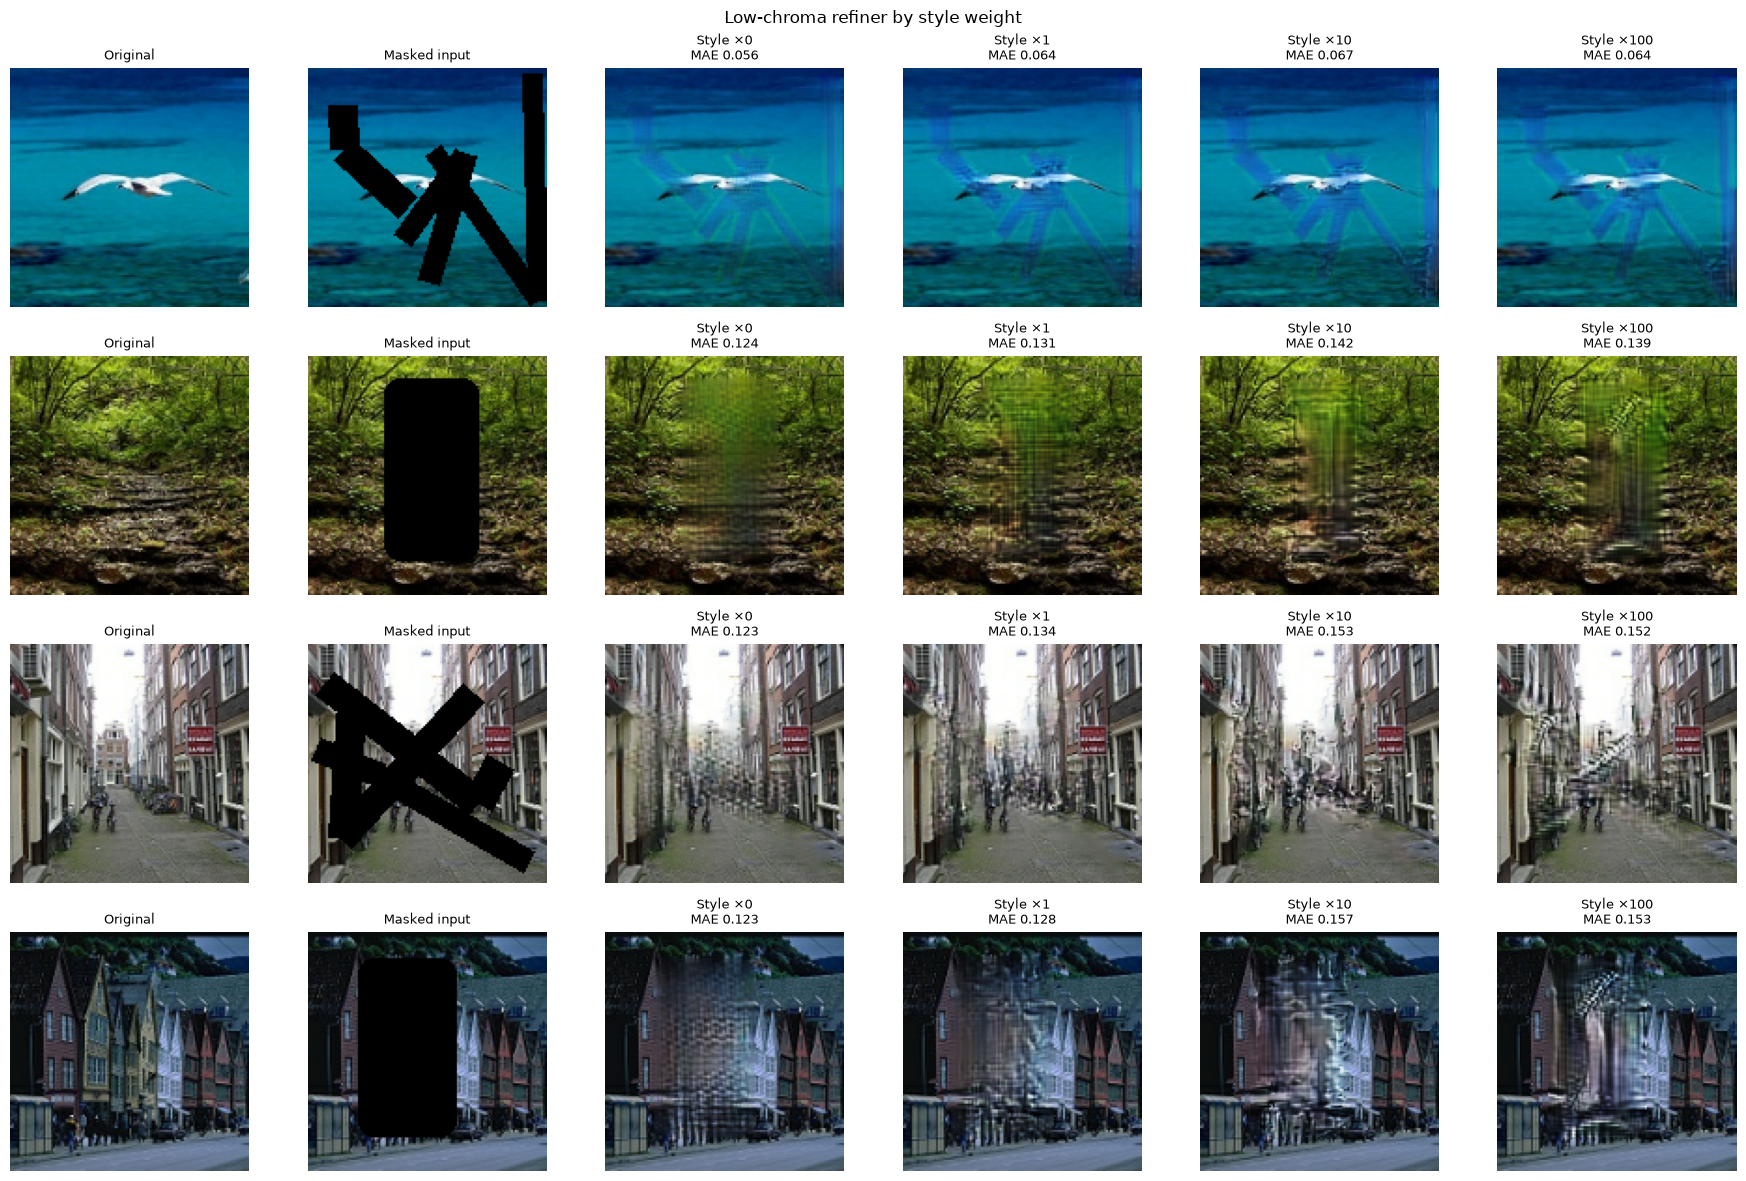

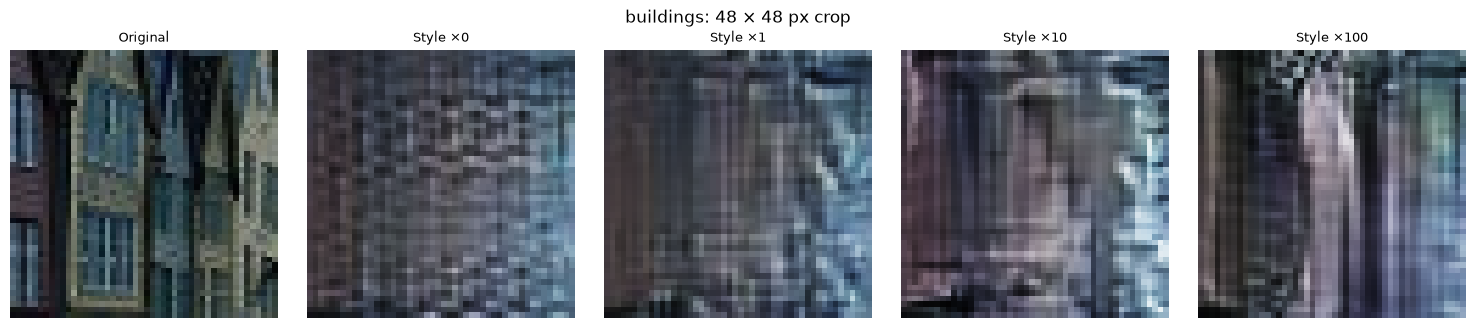

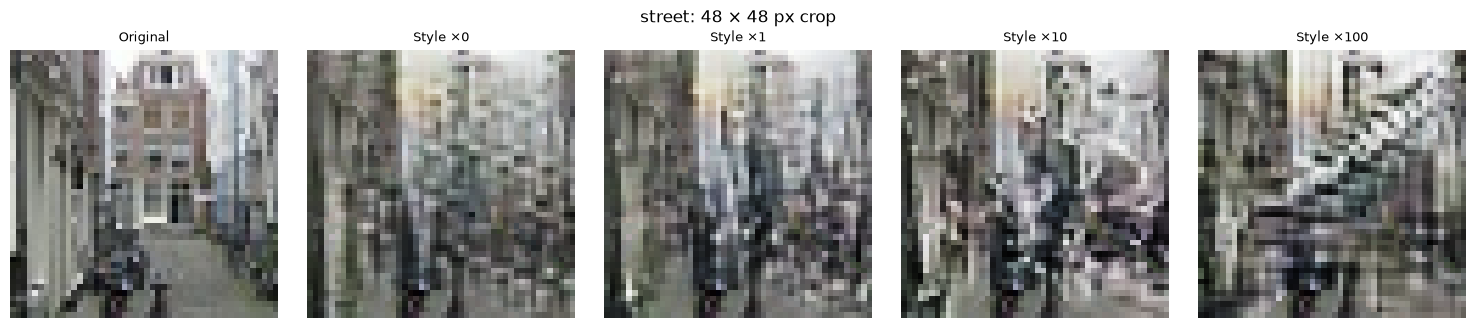

In [13]:
from photo_retouch.plotting import show_zoom

style_results = {
    f"Style ×{multiple}": reconstructions[name]
    for multiple, (name, _) in STYLE_SERIES.items()
}
show_comparison(validation, style_results, examples, "Low-chroma refiner by style weight")

for category, index in zip(
    ["buildings", "street"], validation.example_indices(["buildings", "street"])
):
    show_zoom(validation, style_results, index, title=f"{category}: 48 × 48 px crop")

### Style-Weight Results

**The criterion is not met. The low-chroma refiner (×1) remains the best
candidate.**

- **Grid.** Neither variant lowers all four grid components. At ×10 the
  horizontal 2-px component falls from 0.028 to 0.004 (true images: 0.0004),
  the vertical one halves (0.032 to 0.016), and the vertical 4-px component
  nears the true level (0.006 vs 0.005). The horizontal 4-px component does
  not change (0.0108 vs 0.0107; true images: 0.0046). ×100 is worse than
  ×10 on three of the four components.
- **Perceptual distance** worsens as the weight grows: +0.050 at ×10
  (95% CI [+0.043, +0.057]) and +0.094 at ×100 ([+0.084, +0.104]), compared
  with ×1. KID × 1000 rises by 0.70 and 1.70. Both rises are below one subset
  standard deviation (about 2), so they count as ties, but the new variants
  are lower in only 2% and 0% of the subsets. Masked MAE rises by 0.0085
  and 0.0104.
- **Visually,** the stronger weight replaces the mosaic with other regular
  artifacts rather than natural texture: vertical streaks and smeared
  facades at ×10, diagonal checkered bands at ×100 (the building and street
  crops, and the top of the forest fill). The amount of fine luminance
  detail now matches the truth (ratio 1.02 and 1.04, against 0.81 at ×1).
  The remaining problem is how that detail is arranged, not how much of it
  there is.

**The style loss stops falling.** Over the last 250 updates, the Gram
distance the refiner reaches is 512 without style, 407 at ×1, 391 at ×10,
and 406 at ×100. Raising the weight a hundredfold does not lower the style
loss. It raises the masked L1 (0.105 to 0.116) and the unweighted perceptual
loss (266 to 291). Within 3,000 updates, this refiner cannot match the true
texture statistics any more closely, however strongly it is pushed to.
Hypothesis 1 (style weight too small) is not supported over this range.

**Next.** The mosaic is not a weighting problem. Its 2- and 4-px periods
match the refiner's two nearest-neighbour upsampling stages (hypothesis 2).
They also match two parts of the losses: the first two pooling stages of
the VGG16 layers behind the perceptual and style terms, and the stride-2
convolutions of the discriminator, which the adversarial gradient passes
through. Changing only the upsampling would test hypothesis 2, but
a null result would not separate the other two sources.

**Limitations.** Each variant is a single training run. The perceptual
distance shares VGG16 with the training losses, although here it penalizes
the variants trained with more style.